## Interval Analysis

In [1]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64
torch.set_num_threads(1)

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


Out[1]: 
Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)


In [2]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [3]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 2.012
Epoch 2/15, Loss: 1.729
Epoch 3/15, Loss: 1.627
Epoch 4/15, Loss: 1.596
Epoch 5/15, Loss: 1.582
Epoch 6/15, Loss: 1.572
Epoch 7/15, Loss: 1.566
Epoch 8/15, Loss: 1.561
Epoch 9/15, Loss: 1.557
Epoch 10/15, Loss: 1.553
Epoch 11/15, Loss: 1.550
Epoch 12/15, Loss: 1.547
Epoch 13/15, Loss: 1.545
Epoch 14/15, Loss: 1.542
Epoch 15/15, Loss: 1.540
Accuracy on images: 93.43


### Write the interval analysis for the simple model

In [4]:
def interval_linear(lower, upper, weight, bias):
    center = (lower + upper) / 2
    radius = (upper - lower) / 2
    center = F.linear(center, weight, bias)
    radius = F.linear(radius, weight.abs())
    return center - radius, center + radius


@torch.no_grad()
def margin_lower_bounds(model, x, labels, eps):
    normalize, net = model[0], model[1]

    # Input box and normalization.
    lower = normalize((x - eps).clamp(0, 1)).flatten(start_dim=1)
    upper = normalize((x + eps).clamp(0, 1)).flatten(start_dim=1)

    # First linear layer, then ReLU.
    lower, upper = interval_linear(lower, upper, net.fc.weight, net.fc.bias)
    lower, upper = F.relu(lower), F.relu(upper)

    # Fuse the output layer with logit_y - logit_j.
    weight = net.fc2.weight[labels, None, :] - net.fc2.weight[None, :, :]
    bias = net.fc2.bias[labels, None] - net.fc2.bias[None, :]
    center = (lower + upper) / 2
    radius = (upper - lower) / 2
    return ((weight * center[:, None, :]).sum(dim=-1) + bias
            - (weight.abs() * radius[:, None, :]).sum(dim=-1))


def is_verified(model, x, labels, eps):
    # The y-versus-y margin is exactly zero and does not affect the check.
    return (margin_lower_bounds(model, x, labels, eps) >= 0).all(dim=1)


@torch.no_grad()
def verified_accuracy(model, eps):
    model.eval()
    verified, total = 0, 0
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        verified += is_verified(model, images, labels, eps).sum().item()
        total += labels.size(0)
    return 100 * verified / total


In [5]:
# Zero-radius check
images, labels = next(iter(test_loader))
images, labels = images.to(device), labels.to(device)
with torch.no_grad():
    net = model[1]
    logits = net.fc2(F.relu(net.fc(model[0](images).flatten(start_dim=1))))
    exact = logits.gather(1, labels[:, None]) - logits
    lower = margin_lower_bounds(model, images, labels, 0.0)
    torch.testing.assert_close(lower, exact, atol=2e-5, rtol=1e-4)
    clean_correct = sum((model(x.to(device)).argmax(1) == y.to(device)).sum().item()
                        for x, y in test_loader)
clean_accuracy = 100 * clean_correct / len(test_dataset)
zero_accuracy = verified_accuracy(model, 0.0)
assert zero_accuracy == clean_accuracy
print("Zero-radius margins agree with direct logits.")
print(f"Clean accuracy: {clean_accuracy:.2f}%")
print(f"Verified accuracy at eps=0: {zero_accuracy:.2f}%")


Zero-radius margins agree with direct logits.
Clean accuracy: 93.43%
Verified accuracy at eps=0: 93.43%


In [6]:
# Verified accuracy on the full test set
epsilons = np.linspace(0.01, 0.1, 10)
results = []

for eps in epsilons:
    start = time.time()
    accuracy = verified_accuracy(model, eps)
    results.append(accuracy)
    print(f"eps = {eps:.2f}   verified accuracy = {accuracy:6.2f}%   ({time.time() - start:.1f}s)")

eps = 0.01   verified accuracy =  70.55%   (0.3s)
eps = 0.02   verified accuracy =  23.68%   (0.3s)
eps = 0.03   verified accuracy =   4.56%   (0.3s)
eps = 0.04   verified accuracy =   0.58%   (0.3s)
eps = 0.05   verified accuracy =   0.02%   (0.3s)
eps = 0.06   verified accuracy =   0.00%   (0.3s)
eps = 0.07   verified accuracy =   0.00%   (0.3s)
eps = 0.08   verified accuracy =   0.00%   (0.3s)
eps = 0.09   verified accuracy =   0.00%   (0.3s)
eps = 0.10   verified accuracy =   0.00%   (0.3s)


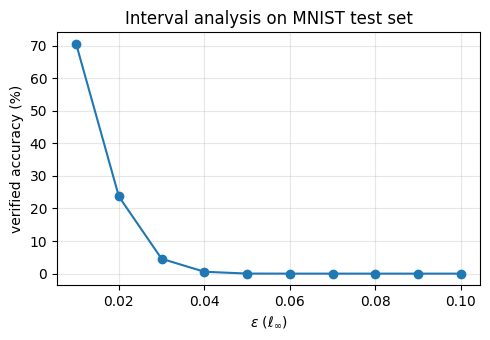

In [7]:
plt.figure(figsize=(5, 3.5))
plt.plot(epsilons, results, marker="o")
plt.xlabel(r"$\epsilon$ ($\ell_\infty$)")
plt.ylabel("verified accuracy (%)")
plt.title("Interval analysis on MNIST test set")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("verified_accuracy.png", dpi=200)
plt.show()

In [8]:
# Random perturbation check
eps = 0.01
images, labels = next(iter(test_loader))

images, labels = images.to(device), labels.to(device)

with torch.no_grad():
    verified = is_verified(model, images, labels, eps)
    for _ in range(100):
        noise = eps * (2 * torch.rand_like(images) - 1)
        perturbed = (images + noise).clamp(0, 1)
        predictions = model(perturbed).argmax(dim=1)
        assert (predictions[verified] == labels[verified]).all()

print(f"{verified.sum().item()} verified images in batch, no counterexample found")

51 verified images in batch, no counterexample found
